This notebook generates the plots in Figure 2 of "Wasting is essential: cachexia is driven by a wound-healing adaptation" by Haynes, Whelan, and Brown.

In [11]:
import numpy as np

import matplotlib.pyplot as plt

from reaction_flask import ReactionFlask

In [19]:
timeValuesList = []
woundValuesList = []
weightValuesList = []
aminoAcidValuesList = []

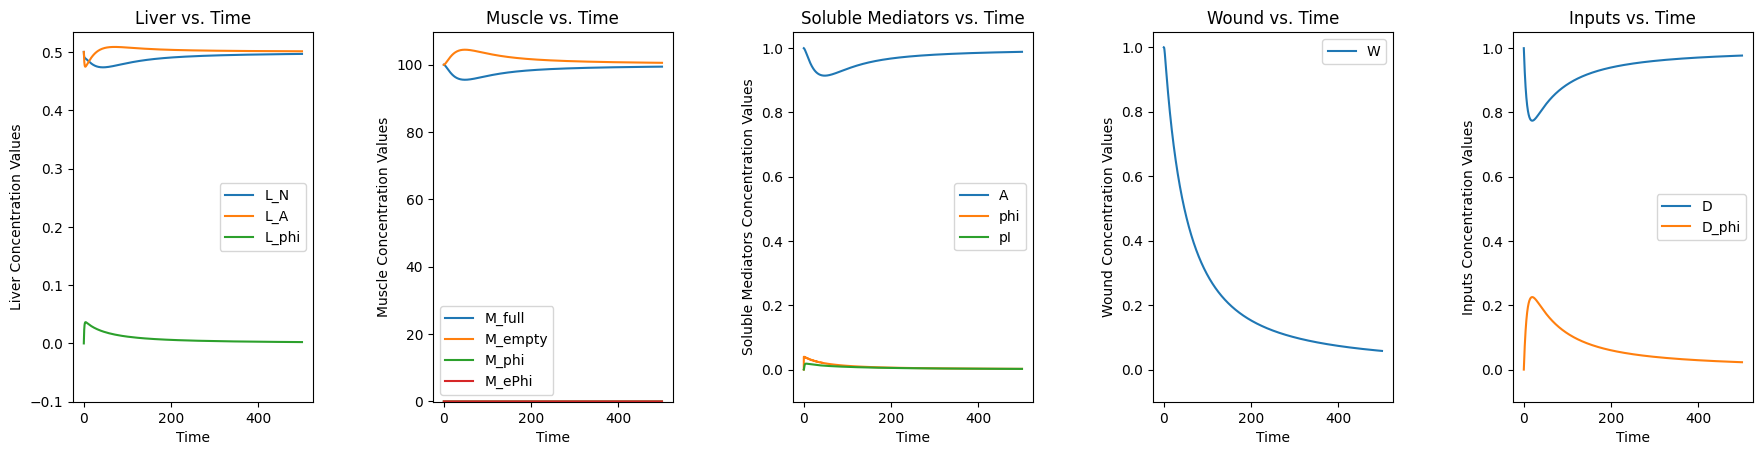

Final value of W: 0.057660389892736544


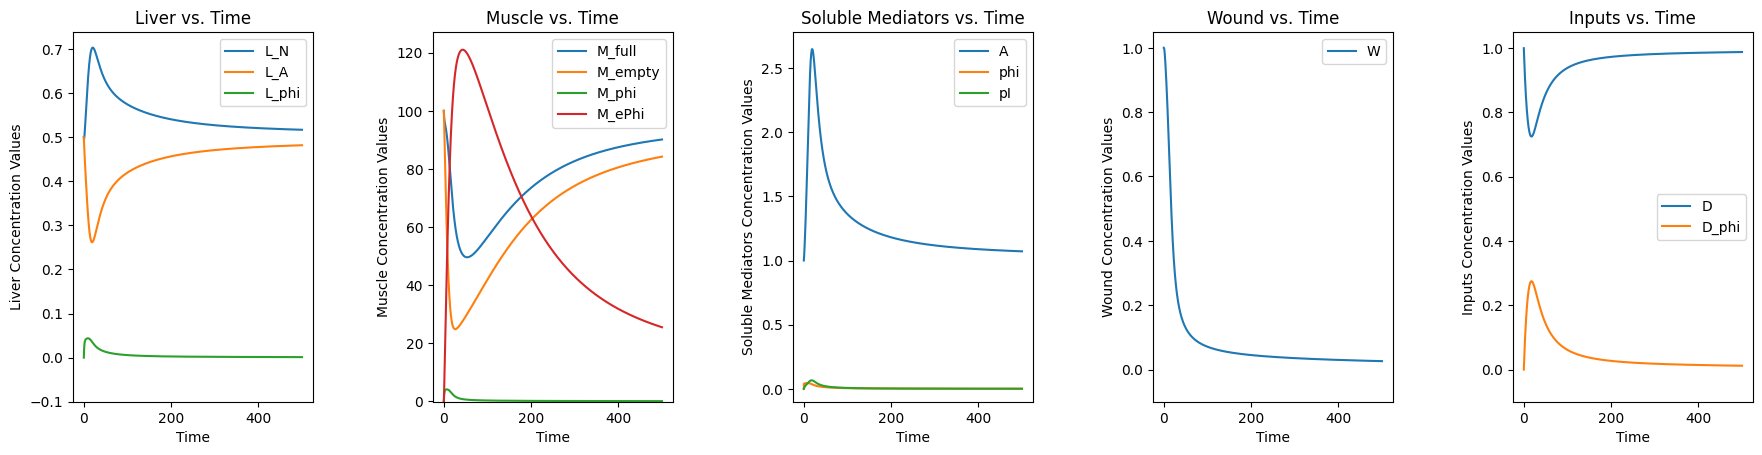

Final value of W: 0.02610529668749695


In [20]:
initWound = 1

diet = 1

woundValsVsTime = []

rxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_A', 'L_phi'], "Muscle" : ['M_full', 'M_empty', 'M_phi', 'M_ePhi'], "Soluble Mediators" : ['A', 'phi', 'pI'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

rxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0])


rxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
rxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
rxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
rxnFlask.addReaction("Reaction 12: W -> W + phi", 8, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
rxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
rxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
rxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
rxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
rxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
rxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
rxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#
#This allows S_full to continue acting as an inflammation sink without changing state
#rxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
#rxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


#This allows S_empty to continue acting as an inflammation sink without changing state
#rxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
#rxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
rxnFlask.addReaction("Reaction 7: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
rxnFlask.addReaction("Reaction 22: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
rxnFlask.addReaction("Reaction 8: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
rxnFlask.addReaction("Reaction 23: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})


for j in range(2):

    if j == 0:
        #This allows M_full to continue acting as an inflammation sink while not changing state
        rxnFlask.modifyReaction("Reaction 7: M_full + g * phi -> M_phi" , newRxnRate = 0)
        rxnFlask.modifyReaction("Reaction 22: M_full + g * phi -> M_full" , newRxnRate = 1)

        #This allows M_empty to continue acting as an inflammation sink while not changing state
        rxnFlask.modifyReaction("Reaction 8: M_empty + g * phi -> M_ePhi" ,newRxnRate = 0)
        rxnFlask.modifyReaction("Reaction 23: M_empty + g * phi -> M_empty", newRxnRate = 1)

    else:
        #This allows M_full to continue acting as an inflammation sink while not changing state
        rxnFlask.modifyReaction("Reaction 7: M_full + g * phi -> M_phi" , newRxnRate = 1)
        rxnFlask.modifyReaction("Reaction 22: M_full + g * phi -> M_full" , newRxnRate = 0)

        #This allows M_empty to continue acting as an inflammation sink while not changing state
        rxnFlask.modifyReaction("Reaction 8: M_empty + g * phi -> M_ePhi" ,newRxnRate = 1)
        rxnFlask.modifyReaction("Reaction 23: M_empty + g * phi -> M_empty", newRxnRate = 0)

    reactionDerivative1 = rxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.5, 0.0, 0.5, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    rxnFlask.runSystem(500)

    rxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = rxnFlask.latestSimulationOutput["t"]

    timeValuesList.append(timeValues)

    print(f"Final value of W: {rxnFlask.getFinalValueOfSpecies('W')}")

    woundValues = rxnFlask.latestSimulationOutput['y'][0]

    woundValuesList.append(woundValues)

    weightValues = rxnFlask.latestSimulationOutput['y'][6]

    weightValuesList.append(weightValues)

    aminoAcidValues = rxnFlask.latestSimulationOutput['y'][10]

    aminoAcidValuesList.append(aminoAcidValues)

    rxnFlask.resetInitialCondition()


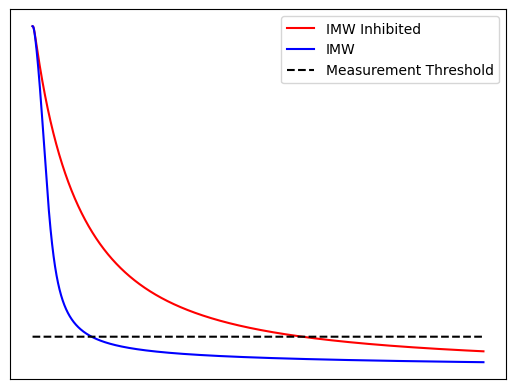

In [17]:
#Weight is twice the storage value since muscle and storage are
#being used equally

figure1, axis1 = plt.subplots()

axis1.plot(timeValuesList[0], woundValuesList[0], label = "IMW Inhibited", color = 'r')
#plt.fill_between(timeValuesList[0], [100 for k in range(len(timeValuesList[0]))], woundValsVsTime[0], color = 'r')

axis1.plot(timeValuesList[1], woundValuesList[1], label = "IMW", color = 'b')
#plt.fill_between(timeValuesList[1], [100 for k in range(len(timeValuesList[1]))], woundValsVsTime[1], color = 'b')

axis1.plot(timeValuesList[0], [0.1 for k in range(len(timeValuesList[0]))], 'k--', label = "Measurement Threshold")

axis1.set_xticks([])
axis1.set_yticks([])

axis1.legend()
plt.savefig("FigureImages/Figure2Images/WoundHealingVsTimeBetweenTwoTreatments.png")
plt.show()

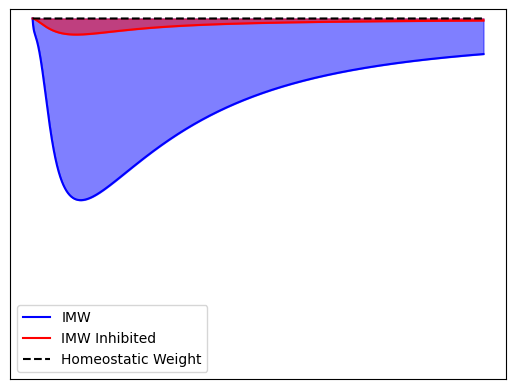

In [24]:
figure2, axis2 = plt.subplots()

axis2.plot(timeValuesList[1], weightValuesList[1], label = "IMW", color = 'b')
axis2.fill_between(timeValuesList[1], [100 for k in range(len(timeValuesList[1]))], weightValuesList[1], color = 'b', alpha = 0.5)

axis2.plot(timeValuesList[0], weightValuesList[0], label = "IMW Inhibited", color = 'r')
axis2.fill_between(timeValuesList[0], [100 for k in range(len(timeValuesList[0]))], weightValuesList[0], color = 'r', alpha = 0.5)

axis2.plot(timeValuesList[0], [100 for k in range(len(timeValuesList[0]))], 'k--', label = "Homeostatic Weight")

axis2.set_ylim(bottom = -0.01)

axis2.set_xticks([])
axis2.set_yticks([])

axis2.legend()
plt.savefig("FigureImages/Figure2Images/WeightVsTimeBetweenTwoTreatments.png")
plt.show()

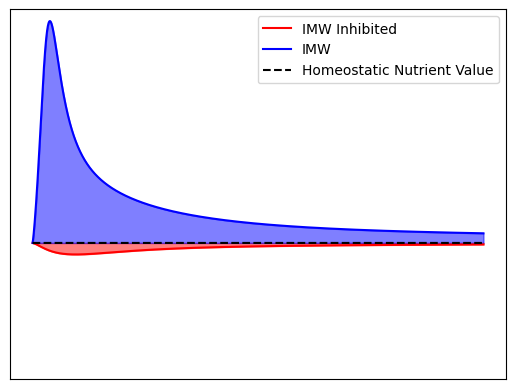

In [25]:
figure3, axis3 = plt.subplots()

axis3.plot(timeValuesList[0], aminoAcidValuesList[0], label = "IMW Inhibited", color = 'r')
axis3.fill_between(timeValuesList[0], [1 for k in range(len(timeValuesList[0]))], aminoAcidValuesList[0], color = 'r', alpha = 0.5)

axis3.plot(timeValuesList[1], aminoAcidValuesList[1], label = "IMW", color = 'b')
axis3.fill_between(timeValuesList[1], [1 for k in range(len(timeValuesList[1]))], aminoAcidValuesList[1], color = 'b', alpha = 0.5)

axis3.plot(timeValuesList[0], [1 for k in range(len(timeValuesList[0]))], 'k--', label = "Homeostatic Nutrient Value")

axis3.set_ylim(bottom = -0.01)

axis3.set_xticks([])
axis3.set_yticks([])

axis3.legend()
plt.savefig("FigureImages/Figure2Images/AminoAcidsVsTimeBetweenTwoTreatments.png")
plt.show()